In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration
json_path = './local/2026-16-10-3-rq/test_output/index_rqvae_prod.json'  # Replace with your file path
num_codes = 256                      # Set to None to auto-infer from max code index

# 1. Load data
with open(json_path, 'r') as f:
    data = json.load(f)

# Convert to DataFrame (rows = items, columns = stage_0 to stage_3)
df = pd.DataFrame.from_dict(data, orient='index')

df.index = df.index.astype(int)
num_stages = df.shape[1]

if num_codes is None:
    num_codes = int(df.max().max()) + 1

print(f"Dataset summary:")
print(f" - Total items: {len(df)}")
print(f" - Number of stages: {num_stages}")
print(f" - Codebook size: {num_codes}")

Dataset summary:
 - Total items: 4783154
 - Number of stages: 5
 - Codebook size: 256


In [3]:
df.head()

,0,1,2,3,4
26,76,73,51,14,0
3492133,76,73,51,14,1
521243,76,73,51,14,2
1986772,76,73,51,14,3
3721438,76,73,51,14,4


Explore the collision

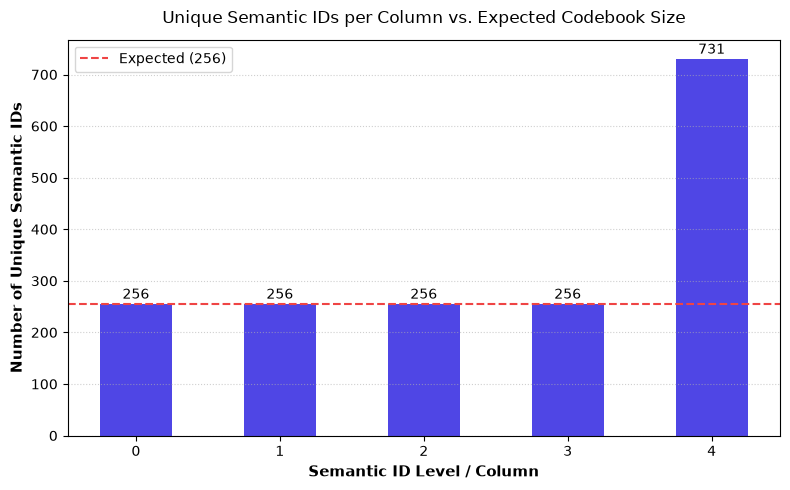

In [33]:
import matplotlib.pyplot as plt
import pandas as pd

# Assuming your dataframe is named 'df' and columns 0 through 4 represent the semantic ID levels:
# Drop the index column if it was captured as part of df, or select only the feature columns:
semantic_cols = [0, 1, 2, 3, 4]  # Adjust if column names are strings like '0', '1', etc.

# Calculate unique counts per column
unique_counts = df[semantic_cols].nunique()

# Plotting the bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(
    [str(col) for col in semantic_cols],
    unique_counts,
    color="#4f46e5",
    width=0.5,
)

# Add dashed reference line for expected codebook size (256)
plt.axhline(
    y=256,
    color="#ef4444",
    linestyle="--",
    linewidth=1.5,
    label="Expected (256)",
)

# Styling details
plt.xlabel("Semantic ID Level / Column", fontsize=11, fontweight="bold")
plt.ylabel("Number of Unique Semantic IDs", fontsize=11, fontweight="bold")
plt.title(
    "Unique Semantic IDs per Column vs. Expected Codebook Size",
    fontsize=12,
    pad=12,
)
plt.grid(axis="y", linestyle=":", alpha=0.6)
plt.legend()

# Display value labels on top of bars
for bar in bars:
  height = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2.0,
      height + 3,
      f"{height}",
      ha="center",
      va="bottom",
      fontsize=10,
  )

plt.tight_layout()
plt.show()

Total entries: 4,783,154
Unique (without last index): 3,459,854
Unique (clamped last index): 4,781,908
Unique (with all indices): 4,783,154


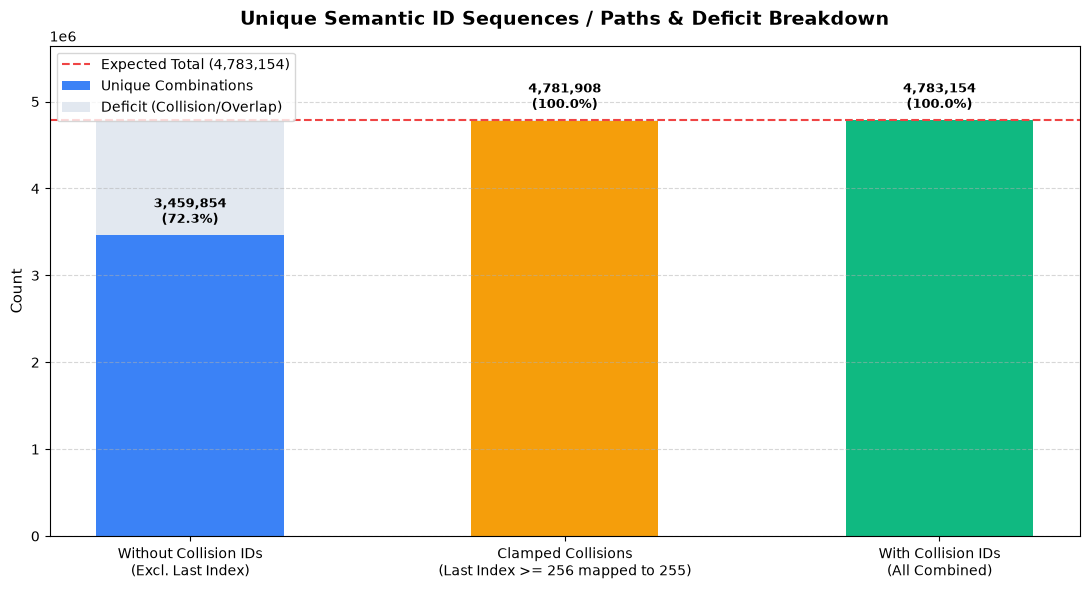

In [34]:
import matplotlib.pyplot as plt
import pandas as pd

# Define your semantic ID columns (adjust names if they are strings like ['0', '1', '2', '3', '4'])
semantic_cols = [0, 1, 2, 3, 4]
data_matrix = df[semantic_cols].values

total_entries = len(df)

# 1. Unique sequence calculations matching your logic
tuples_without = [tuple(v[:-1]) for v in data_matrix if len(v) > 1]
unique_count_without = len(set(tuples_without))

tuples_clamped = []
for v in data_matrix:
  if len(v) > 0:
    lst = list(v)
    if lst[-1] >= 256:
      lst[-1] = 255
    tuples_clamped.append(tuple(lst))
unique_count_clamped = len(set(tuples_clamped))

tuples_with = [tuple(v) for v in data_matrix]
unique_count_with = len(set(tuples_with))

print(f"Total entries: {total_entries:,}")
print(f"Unique (without last index): {unique_count_without:,}")
print(f"Unique (clamped last index): {unique_count_clamped:,}")
print(f"Unique (with all indices): {unique_count_with:,}")

# --- Plotting Stacked Bars (Actual + Deficit to Expected Total) ---
categories = [
    "Without Collision IDs\n(Excl. Last Index)",
    "Clamped Collisions\n(Last Index >= 256 mapped to 255)",
    "With Collision IDs\n(All Combined)",
]

actual_counts = [unique_count_without, unique_count_clamped, unique_count_with]
deficits = [total_entries - count for count in actual_counts]

fig, ax = plt.subplots(figsize=(11, 6))

# Main bars (Actual Unique Counts)
bars_actual = ax.bar(
    categories,
    actual_counts,
    width=0.5,
    color=["#3b82f6", "#f59e0b", "#10b981"],
    edgecolor="none",
    label="Unique Combinations",
)
# Deficit bars (Stacked on top)
bars_deficit = ax.bar(
    categories,
    deficits,
    bottom=actual_counts,
    width=0.5,
    color="#e2e8f0",
    edgecolor="none",
    label="Deficit (Collision/Overlap)",
)

# Value labels on top of actual bars
for bar, count in zip(bars_actual, actual_counts):
  height = bar.get_height()
  pct = (count / total_entries) * 100.0 if total_entries > 0 else 0
  ax.annotate(
      f"{count:,}\n({pct:.1f}%)",
      xy=(bar.get_x() + bar.get_width() / 2, height),
      xytext=(0, 6),
      textcoords="offset points",
      ha="center",
      va="bottom",
      fontsize=9,
      fontweight="bold",
  )

ax.axhline(
    total_entries,
    color="#ef4444",
    linestyle="--",
    linewidth=1.5,
    label=f"Expected Total ({total_entries:,})",
)

ax.set_title(
    "Unique Semantic ID Sequences / Paths & Deficit Breakdown",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_ylabel("Count", fontsize=11)
ax.set_ylim(0, total_entries * 1.18)  # Headroom for annotations
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [23]:
# Remove the last column (Stage 5 / collision ID)
df = df.iloc[:, :-1]
num_stages = df.shape[1]

print(f"Updated dataset summary:")
print(f" - Remaining stages for code analysis: {num_stages}")
print(f" - New DataFrame shape: {df.shape}")

Updated dataset summary:
 - Remaining stages for code analysis: 3
 - New DataFrame shape: (4783154, 3)


# Quick Metrics

In [16]:
metrics = []
total_items = len(df)

for stage_idx in range(num_stages):
    stage_col = df.columns[stage_idx]
    
    # n_{s,k}: counts of items assigned to each code
    counts = df[stage_col].value_counts().reindex(range(num_codes), fill_value=0)
    
    # p_{s,k}: fraction of items assigned to code k
    probs = counts / total_items
    
    # Code utilization: U_s = #{k: n_{s,k} > 0} / K_s
    active_codes = (counts > 0).sum()
    code_utilization = active_codes / num_codes
    
    # Dead-code ratio: D_s = #{k: n_{s,k} = 0} / K_s
    dead_codes = (counts == 0).sum()
    dead_code_ratio = dead_codes / num_codes
    
    # Assignment entropy: H_s = -\sum p_{s,k} \log_2 p_{s,k} (using base-2 for bits)
    non_zero_probs = probs[probs > 0]
    entropy = -np.sum(non_zero_probs * np.log2(non_zero_probs))
    
    # Effective codebook size (perplexity): P_s = 2^{H_s} (using base-2 exponential matching log_2 entropy)
    perplexity = 2 ** entropy
    
    max_usage = counts.max()
    
    metrics.append({
        'Stage': f'Stage {stage_idx + 1}',
        'Code Utilization (U_s)': code_utilization,
        'Dead-Code Ratio (D_s)': dead_code_ratio,
        'Active Codes': active_codes,
        'Dead Codes': dead_codes,
        'Entropy (bits)': entropy,
        'Perplexity (P_s)': perplexity,
        'Max Code Usage Count': max_usage
    })
    
    print(f"Stage {stage_idx + 1}:")
    print(f"  - Code Utilization (U_s): {code_utilization:.4f} ({active_codes}/{num_codes} active)")
    print(f"  - Dead-Code Ratio (D_s): {dead_code_ratio:.4f} ({dead_codes} dead)")
    print(f"  - Shannon Entropy (H_s): {entropy:.2f} bits")
    print(f"  - Perplexity / Effective Size (P_s): {perplexity:.2f}\n")
    
metrics_df = pd.DataFrame(metrics)
display(metrics_df)

Stage 1:
  - Code Utilization (U_s): 1.0000 (256/256 active)
  - Dead-Code Ratio (D_s): 0.0000 (0 dead)
  - Shannon Entropy (H_s): 7.92 bits
  - Perplexity / Effective Size (P_s): 242.92

Stage 2:
  - Code Utilization (U_s): 1.0000 (256/256 active)
  - Dead-Code Ratio (D_s): 0.0000 (0 dead)
  - Shannon Entropy (H_s): 7.87 bits
  - Perplexity / Effective Size (P_s): 234.58

Stage 3:
  - Code Utilization (U_s): 1.0000 (256/256 active)
  - Dead-Code Ratio (D_s): 0.0000 (0 dead)
  - Shannon Entropy (H_s): 7.93 bits
  - Perplexity / Effective Size (P_s): 244.51

Stage 4:
  - Code Utilization (U_s): 1.0000 (256/256 active)
  - Dead-Code Ratio (D_s): 0.0000 (0 dead)
  - Shannon Entropy (H_s): 7.98 bits
  - Perplexity / Effective Size (P_s): 252.55



,Stage,Code Utilization (U_s),Dead-Code Ratio (D_s),Active Codes,Dead Codes,Entropy (bits),Perplexity (P_s),Max Code Usage Count
0,Stage 1,1.0,0.0,256,0,7.924321,242.917285,39883
1,Stage 2,1.0,0.0,256,0,7.873919,234.577150,43127
2,Stage 3,1.0,0.0,256,0,7.933734,244.507310,30121
3,Stage 4,1.0,0.0,256,0,7.980415,252.548159,25603


# Code Frequency Distribution

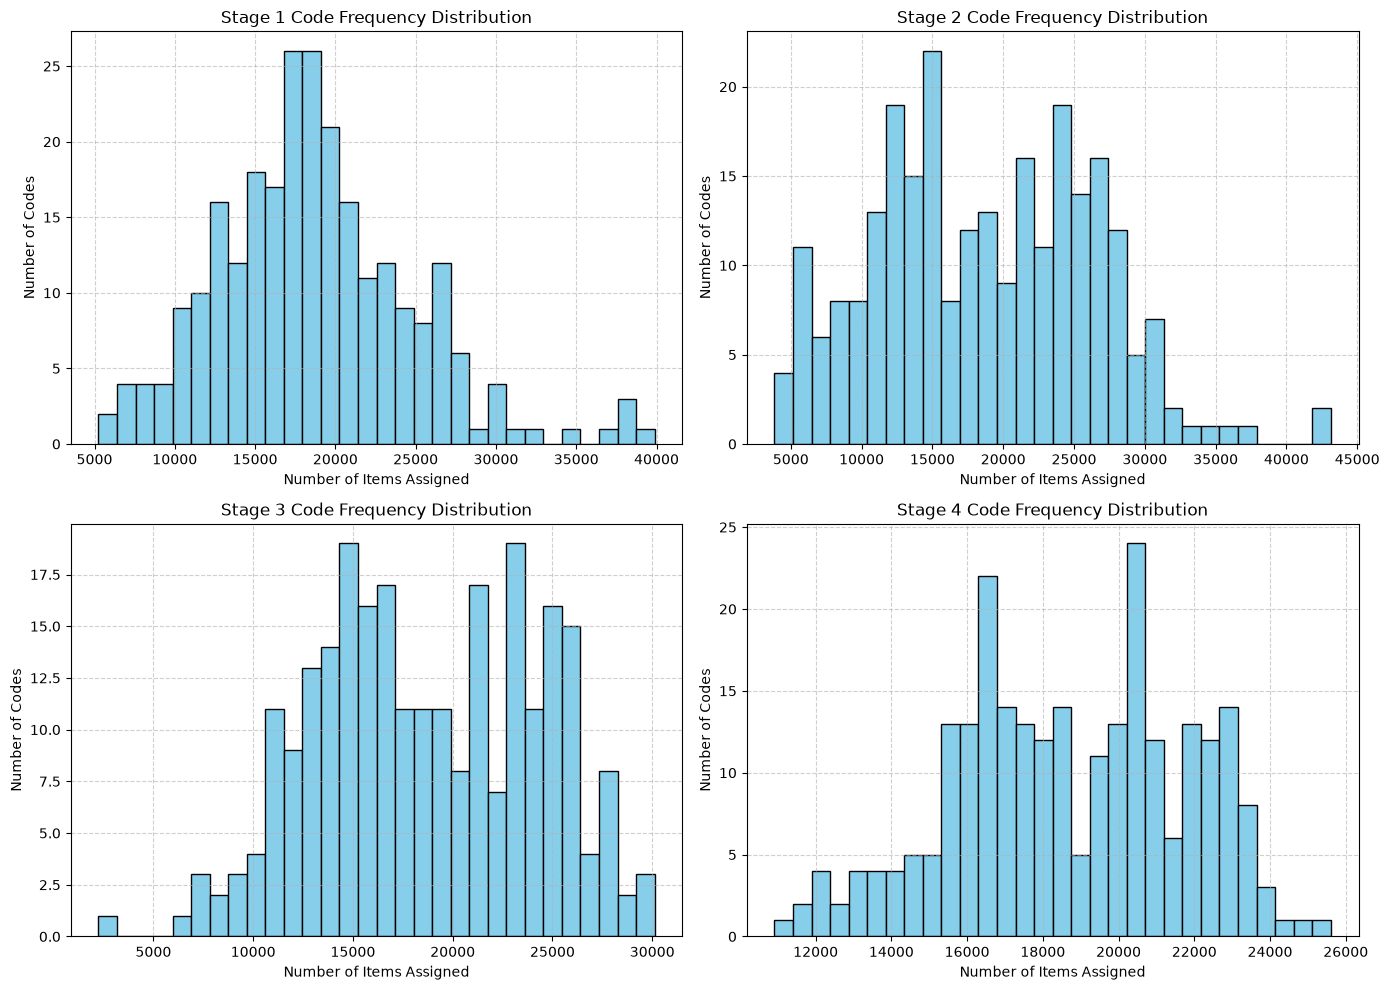

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for stage_idx in range(num_stages):
    stage_col = df.columns[stage_idx]
    counts = df[stage_col].value_counts()
    
    axes[stage_idx].hist(counts, bins=30, color='skyblue', edgecolor='black')
    axes[stage_idx].set_title(f'Stage {stage_idx + 1} Code Frequency Distribution')
    axes[stage_idx].set_xlabel('Number of Items Assigned')
    axes[stage_idx].set_ylabel('Number of Codes')
    axes[stage_idx].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Code Utilization Heatmap

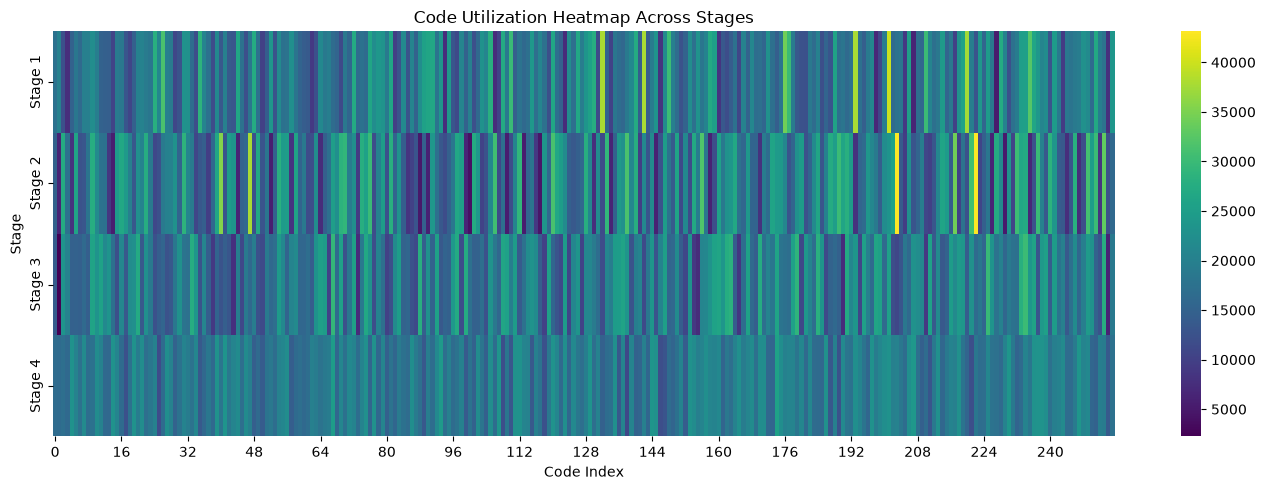

In [18]:
# Create a matrix of shape (num_stages, num_codes)
utilization_matrix = np.zeros((num_stages, num_codes))

for stage_idx in range(num_stages):
    stage_col = df.columns[stage_idx]
    counts = df[stage_col].value_counts()
    for code, count in counts.items():
        if 0 <= int(code) < num_codes:
            utilization_matrix[stage_idx, int(code)] = count

plt.figure(figsize=(14, 5))
sns.heatmap(utilization_matrix, cmap='viridis', cbar=True, 
            xticklabels=max(1, num_codes // 16), 
            yticklabels=[f'Stage {i+1}' for i in range(num_stages)])
plt.title('Code Utilization Heatmap Across Stages')
plt.xlabel('Code Index')
plt.ylabel('Stage')
plt.tight_layout()
plt.show()

# Prefix Growth Chart

--- SID Structure Metrics ---


,Total Items,Unique Full SIDs,Duplicate SID Rate,Depth 1,Depth 2,Depth 3,Depth 4
0,4783154,3459854,27.67%,256,57122,1506041,3459854


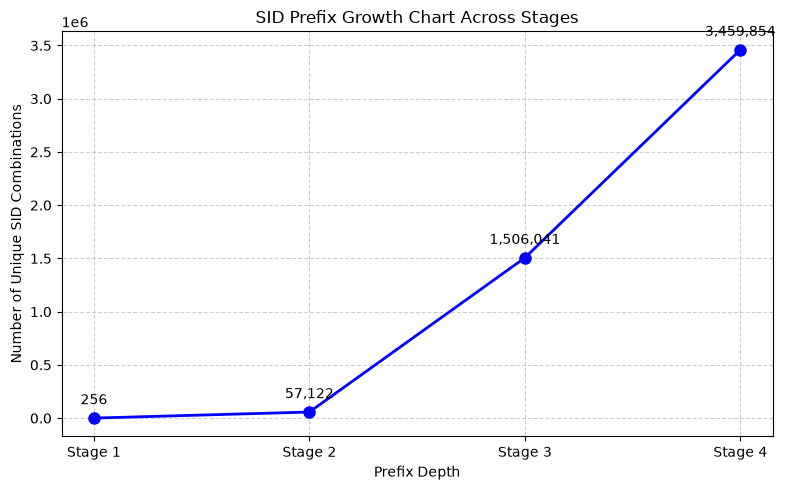

In [19]:
total_items = len(df)
num_stages_catalog = df.shape[1]

# Convert DataFrame to a NumPy array for fast operations
data_arr = df.to_numpy()

# 1. Calculate unique full SIDs and duplicate rate using structured view (much faster than apply)
# Convert rows to structured array bytes to quickly find unique items
struct_arr = np.ascontiguousarray(data_arr).view(np.dtype((np.void, data_arr.dtype.itemsize * data_arr.shape[1])))
unique_full_sids = len(np.unique(struct_arr))
duplicate_sid_rate = 1.0 - (unique_full_sids / total_items)

# 2. Calculate unique prefixes efficiently stage by stage
prefix_counts = []
for depth in range(1, num_stages_catalog + 1):
    sub_arr = data_arr[:, :depth]
    sub_struct = np.ascontiguousarray(sub_sub := sub_arr).view(np.dtype((np.void, sub_arr.dtype.itemsize * sub_arr.shape[1])))
    unique_prefixes = len(np.unique(sub_struct))
    
    prefix_counts.append({
        'Depth': f'Depth {depth}',
        'Unique Prefixes': unique_prefixes
    })

# Summary DataFrame
sid_metrics = {
    'Total Items': total_items,
    'Unique Full SIDs': unique_full_sids,
    'Duplicate SID Rate': f"{duplicate_sid_rate * 100:.2f}%",
}
for p in prefix_counts:
    sid_metrics[p['Depth']] = p['Unique Prefixes']

sid_metrics_df = pd.DataFrame([sid_metrics])
print("--- SID Structure Metrics ---")
display(sid_metrics_df)

# 3. Prefix Growth Chart Visualization
depths = [f'Stage {i}' for i in range(1, num_stages_catalog + 1)]
unique_values = [p['Unique Prefixes'] for p in prefix_counts]

plt.figure(figsize=(8, 5))
plt.plot(depths, unique_values, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('SID Prefix Growth Chart Across Stages')
plt.xlabel('Prefix Depth')
plt.ylabel('Number of Unique SID Combinations')
plt.grid(True, linestyle='--', alpha=0.6)

for i, txt in enumerate(unique_values):
    plt.annotate(f"{txt:,}", (depths[i], unique_values[i]), textcoords="offset points", xytext=(0,10), ha='center')

plt.tight_layout()
plt.show()

# Top-Code Frequency Distribution

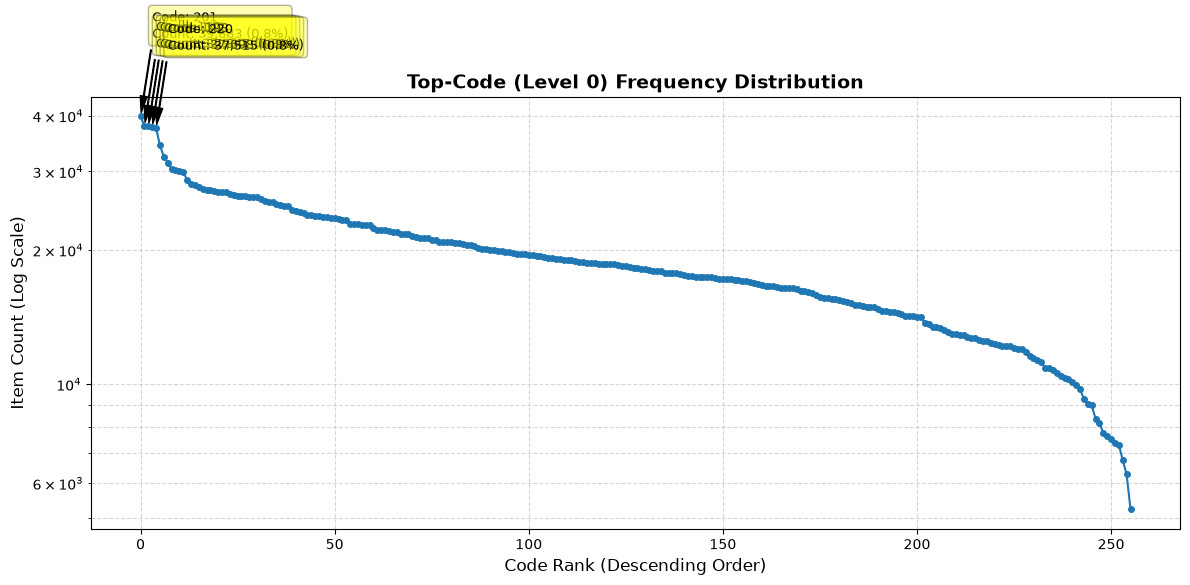

Rank  Code      Count       Percentage
--------------------------------------
1     201       39,883        0.83%
2     132       37,950        0.79%
3     142       37,847        0.79%
4     193       37,698        0.79%
5     220       37,515        0.78%
6     176       34,318        0.72%
7     235       32,367        0.68%
8     26        31,404        0.66%
9     148       30,332        0.63%
10    210       30,185        0.63%


In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Get the frequency distribution of Level 0 (the top-code column named '0')
# This counts how many items fall under each top-code (Level 0)
top_counts = df[0].value_counts().reset_index()
top_counts.columns = ['code', 'count']

# 2. Sort by frequency in descending order
top_counts = top_counts.sort_values(by='count', ascending=False).reset_index(
    drop=True
)

# Calculate percentages based on the total number of items
total_items = top_counts['count'].sum()
top_counts['percentage'] = (top_counts['count'] / total_items) * 100

# 3. Create the plot
plt.figure(figsize=(12, 6))
plt.plot(
    top_counts.index,
    top_counts['count'],
    marker='o',
    linestyle='-',
    color='#1f77b4',
    markersize=4,
)

# Apply logarithmic scale to the y-axis
plt.yscale('log')

# Labels and Title
plt.title(
    'Top-Code (Level 0) Frequency Distribution', fontsize=14, fontweight='bold'
)
plt.xlabel('Code Rank (Descending Order)', fontsize=12)
plt.ylabel('Item Count (Log Scale)', fontsize=12)

# 4. Annotate the most frequent top-codes (e.g., top 5)
top_n = 5
for i in range(min(top_n, len(top_counts))):
  rank = i
  count = top_counts.loc[i, 'count']
  pct = top_counts.loc[i, 'percentage']
  code_val = top_counts.loc[i, 'code']

  plt.annotate(
      f'Code: {code_val}\nCount: {count:,} ({pct:.1f}%)',
      xy=(rank, count),
      xytext=(rank + 3, count * 1.5),
      arrowprops=dict(facecolor='black', shrink=0.05, width=0.5, headwidth=5),
      fontsize=9,
      bbox=dict(boxstyle='round,pad=0.3', fc='yellow', alpha=0.3),
  )

# Formatting grid and layout
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Print the top codes and their stats directly to the console
top_n = 10
print(f"{'Rank':<6}{'Code':<10}{'Count':<12}{'Percentage':<10}")
print("-" * 38)

for i in range(min(top_n, len(top_counts))):
  rank = i + 1
  code_val = top_counts.loc[i, 'code']
  count = top_counts.loc[i, 'count']
  pct = top_counts.loc[i, 'percentage']
  print(f'{rank:<6}{code_val:<10}{count:<12,}{pct:6.2f}%')

Embeddings plot (Geometric Allignment & Semantic Structure)

In [21]:

# ==========================================
# 0. Shared Data Loading and Alignment
# ==========================================
import pyarrow.dataset as ds
import numpy as np
import pandas as pd

# Configuration
PARQUET_PATH = "./local/2026-13-10-1-ei/item_embeddings.parquet"
SAMPLE_SIZE = 50_000
RANDOM_SEED = 42
SID_COLUMNS = [0, 1, 2, 3]

# Reproducible random generator shared by all analyses
rng = np.random.default_rng(RANDOM_SEED)

# 1. Load a reproducible random subset of embeddings
dataset = ds.dataset(PARQUET_PATH, format="parquet")
total_rows = dataset.count_rows()
sample_size = min(SAMPLE_SIZE, total_rows)

sampled_indices = rng.choice(
    total_rows,
    size=sample_size,
    replace=False,
)
sampled_indices.sort()

table = dataset.take(sampled_indices)

item_ids = table.column("item_id").to_numpy()
embeddings_matrix = np.vstack(
    table.column("embedding").to_pylist()
).astype(np.float32)

# 2. Create a common item-indexed embedding DataFrame
embeddings_df = pd.DataFrame(
    embeddings_matrix,
    index=pd.Index(item_ids, name="item_id"),
)

# 3. Validate item ID uniqueness and align SIDs by item ID
assert embeddings_df.index.is_unique, (
    "Embedding item_ids must be unique."
)
assert df.index.is_unique, "SID dataframe index must be unique."
assert set(SID_COLUMNS).issubset(df.columns), (
    f"Missing SID columns: {set(SID_COLUMNS) - set(df.columns)}"
)

missing_sid_ids = embeddings_df.index.difference(df.index)

if len(missing_sid_ids) > 0:
    raise ValueError(
        f"{len(missing_sid_ids)} sampled items have no SID mapping."
    )

# .loc preserves the exact item order in embeddings_df
sid_df = df.loc[embeddings_df.index, SID_COLUMNS].copy()

# Shared NumPy arrays for all downstream analyses
sid_array = sid_df.to_numpy(dtype=np.int64)

# Normalize once for cosine similarity and Faiss
embedding_norms = np.linalg.norm(
    embeddings_matrix, axis=1, keepdims=True
)

if np.any(embedding_norms < 1e-12):
    raise ValueError("Zero-norm embeddings found in the sample.")

norm_embeddings = embeddings_matrix / embedding_norms

print(f"Total parquet rows: {total_rows:,}")
print(f"Sampled items: {len(embeddings_df):,}")
print(f"Embedding shape: {embeddings_matrix.shape}")
print(f"SID shape: {sid_array.shape}")
print(f"All sampled items have SIDs: {len(missing_sid_ids) == 0}")
print(f"Random seed: {RANDOM_SEED}")

Total parquet rows: 4,783,154
Sampled items: 50,000
Embedding shape: (50000, 256)
SID shape: (50000, 4)
All sampled items have SIDs: True
Random seed: 42


# SID vs Embedding Similarity Plot


--- Cosine Similarity by Matching SID Prefix ---
                 count      mean    median       std
prefix_length                                       
0              49783.0  0.081899  0.073231  0.233626
1                213.0  0.646471  0.664729  0.151704
2                  3.0  0.749387  0.698626  0.136801
3                  1.0  0.947672  0.947672       NaN
4                  NaN       NaN       NaN       NaN


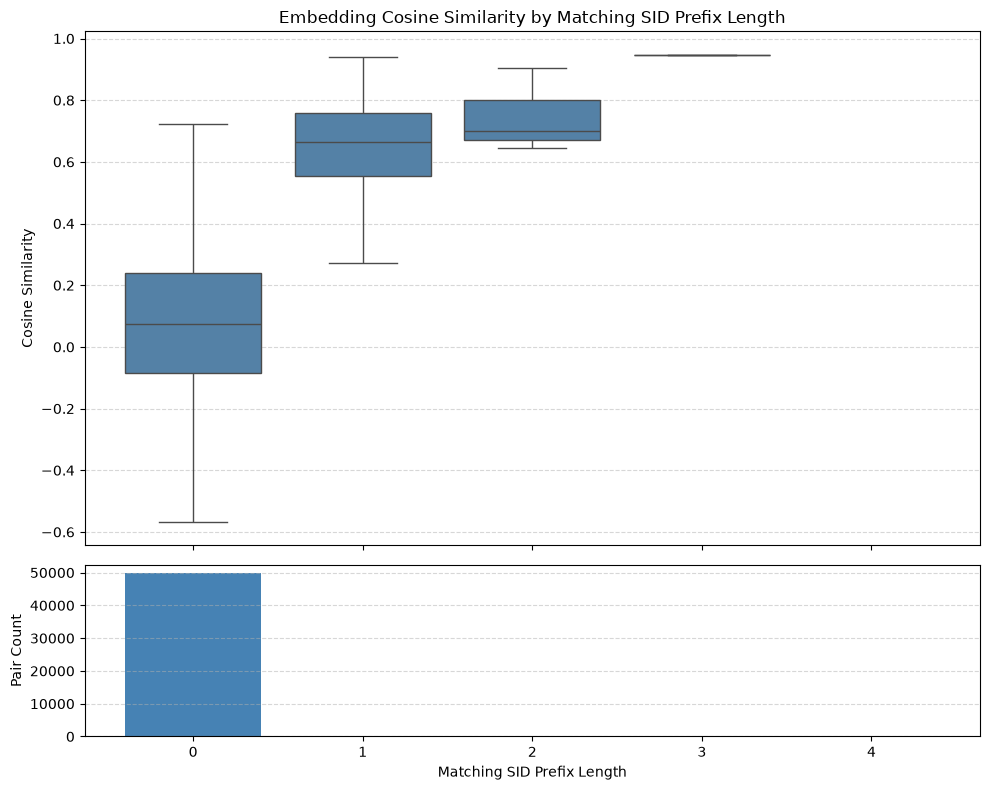

In [24]:

# ==========================================
# A. SID Prefix Length vs. Embedding Similarity
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

NUM_PAIRS = 50_000
n_items = len(norm_embeddings)

if n_items < 2:
    raise ValueError("At least two items are required.")

# 1. Sample reproducible random item pairs
pair_i = rng.integers(0, n_items, size=NUM_PAIRS)
pair_j = rng.integers(0, n_items, size=NUM_PAIRS)

# Avoid pairing an item with itself
same_item = pair_i == pair_j
while np.any(same_item):
    pair_j[same_item] = rng.integers(
        0, n_items, size=int(same_item.sum())
    )
    same_item = pair_i == pair_j

# 2. Calculate cosine similarity with normalized embeddings
pair_cos_sims = np.einsum(
    "ij,ij->i",
    norm_embeddings[pair_i],
    norm_embeddings[pair_j],
)

# 3. Calculate longest matching SID prefix: 0 through 4
pair_sid_i = sid_array[pair_i]
pair_sid_j = sid_array[pair_j]

matching_prefixes = np.zeros(NUM_PAIRS, dtype=np.int8)
still_matching = np.ones(NUM_PAIRS, dtype=bool)

for stage in range(sid_array.shape[1]):
    still_matching &= pair_sid_i[:, stage] == pair_sid_j[:, stage]
    matching_prefixes += still_matching

# 4. Create a common results DataFrame
pair_df = pd.DataFrame({
    "prefix_length": matching_prefixes,
    "cosine_similarity": pair_cos_sims,
})

# 5. Report counts and descriptive statistics
summary = (
    pair_df.groupby("prefix_length")["cosine_similarity"]
    .agg(["count", "mean", "median", "std"])
    .reindex(range(sid_array.shape[1] + 1))
)

print("\n--- Cosine Similarity by Matching SID Prefix ---")
print(summary.to_string())

# 6. Plot distributions and group sample counts
fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 8),
    gridspec_kw={"height_ratios": [3, 1]},
    sharex=True,
)

sns.boxplot(
    data=pair_df,
    x="prefix_length",
    y="cosine_similarity",
    order=range(sid_array.shape[1] + 1),
    color="steelblue",
    showfliers=False,
    ax=axes[0],
)

axes[0].set_title(
    "Embedding Cosine Similarity by Matching SID Prefix Length"
)
axes[0].set_xlabel("")
axes[0].set_ylabel("Cosine Similarity")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

counts = summary["count"].fillna(0).astype(int)

axes[1].bar(
    counts.index,
    counts.values,
    color="steelblue",
)
axes[1].set_xlabel("Matching SID Prefix Length")
axes[1].set_ylabel("Pair Count")
axes[1].set_xticks(range(sid_array.shape[1] + 1))
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Depth 1: sampled 5,000 within-prefix pairs across 256 groups.
Depth 2: sampled 5,000 within-prefix pairs across 10,752 groups.
Depth 3: sampled 5,000 within-prefix pairs across 3,208 groups.
Depth 4: sampled 5,000 within-prefix pairs across 628 groups.

--- Prefix-Conditioned Similarity ---
              count      mean    median       std
prefix_depth                                     
1              5000  0.670498  0.683660  0.143184
2              5000  0.861681  0.879568  0.081259
3              5000  0.928678  0.938305  0.043180
4              5000  0.950063  0.958560  0.036176


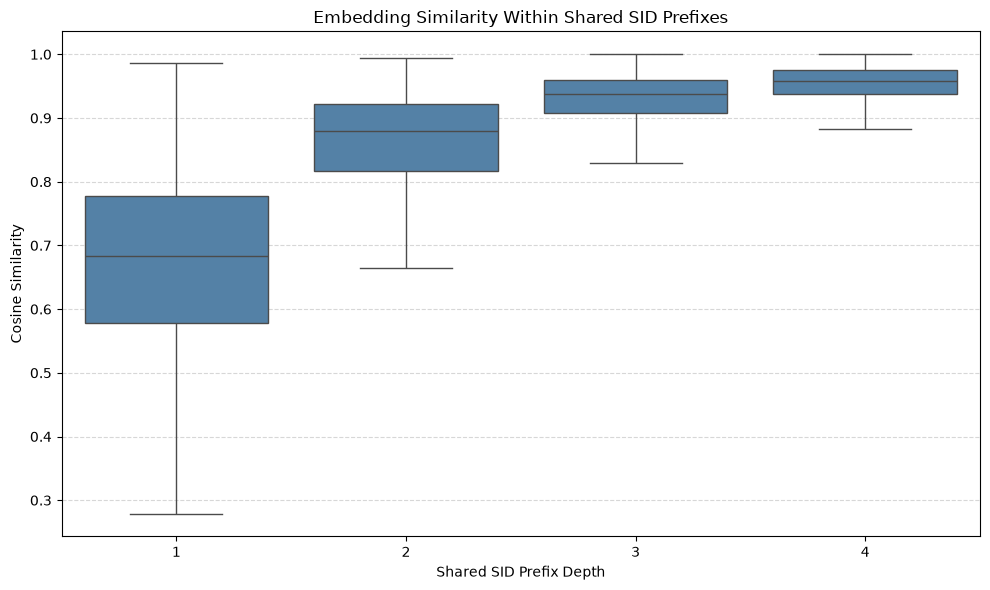

In [25]:

# ==========================================
# A2. Prefix-Conditioned Similarity Analysis
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

NUM_PAIRS_PER_DEPTH = 5_000
n_items = len(sid_array)
n_stages = sid_array.shape[1]

# 1. Group item indices by each SID prefix
prefix_groups = {}

for depth in range(1, n_stages + 1):
    groups = {}

    for i, sid in enumerate(sid_array):
        prefix = tuple(sid[:depth])
        groups.setdefault(prefix, []).append(i)

    prefix_groups[depth] = {
        prefix: np.asarray(indices, dtype=np.int64)
        for prefix, indices in groups.items()
        if len(indices) >= 2
    }

# 2. Sample distinct item pairs within each prefix depth
results = []

for depth, groups in prefix_groups.items():
    eligible_groups = list(groups.values())

    if not eligible_groups:
        print(f"Depth {depth}: no prefix groups contain 2+ items.")
        continue

    # Weight groups by their number of available item pairs.
    group_sizes = np.array(
        [len(indices) for indices in eligible_groups],
        dtype=np.float64,
    )
    group_weights = group_sizes * (group_sizes - 1) / 2
    group_weights /= group_weights.sum()

    sampled_cosines = []
    attempts = 0
    max_attempts = NUM_PAIRS_PER_DEPTH * 20

    while (
        len(sampled_cosines) < NUM_PAIRS_PER_DEPTH
        and attempts < max_attempts
    ):
        attempts += 1

        group_idx = rng.choice(
            len(eligible_groups), p=group_weights
        )
        indices = eligible_groups[group_idx]

        i, j = rng.choice(indices, size=2, replace=False)
        cosine = float(norm_embeddings[i] @ norm_embeddings[j])

        sampled_cosines.append(cosine)

    if not sampled_cosines:
        continue

    for cosine in sampled_cosines:
        results.append({
            "prefix_depth": depth,
            "cosine_similarity": cosine,
        })

    print(
        f"Depth {depth}: sampled {len(sampled_cosines):,} "
        f"within-prefix pairs across {len(eligible_groups):,} groups."
    )

# 3. Summarize
conditioned_df = pd.DataFrame(results)

if not conditioned_df.empty:
    print("\n--- Prefix-Conditioned Similarity ---")
    print(
        conditioned_df.groupby("prefix_depth")["cosine_similarity"]
        .agg(["count", "mean", "median", "std"])
        .to_string()
    )

    # 4. Plot
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=conditioned_df,
        x="prefix_depth",
        y="cosine_similarity",
        color="steelblue",
        showfliers=False,
    )

    plt.title("Embedding Similarity Within Shared SID Prefixes")
    plt.xlabel("Shared SID Prefix Depth")
    plt.ylabel("Cosine Similarity")
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# Umap of Item Embeddings Colored by First-Stage Code

Running UMAP on the shared embedding subset...


c:\Users\justin\Documents\GitHub\NZ5-GR\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


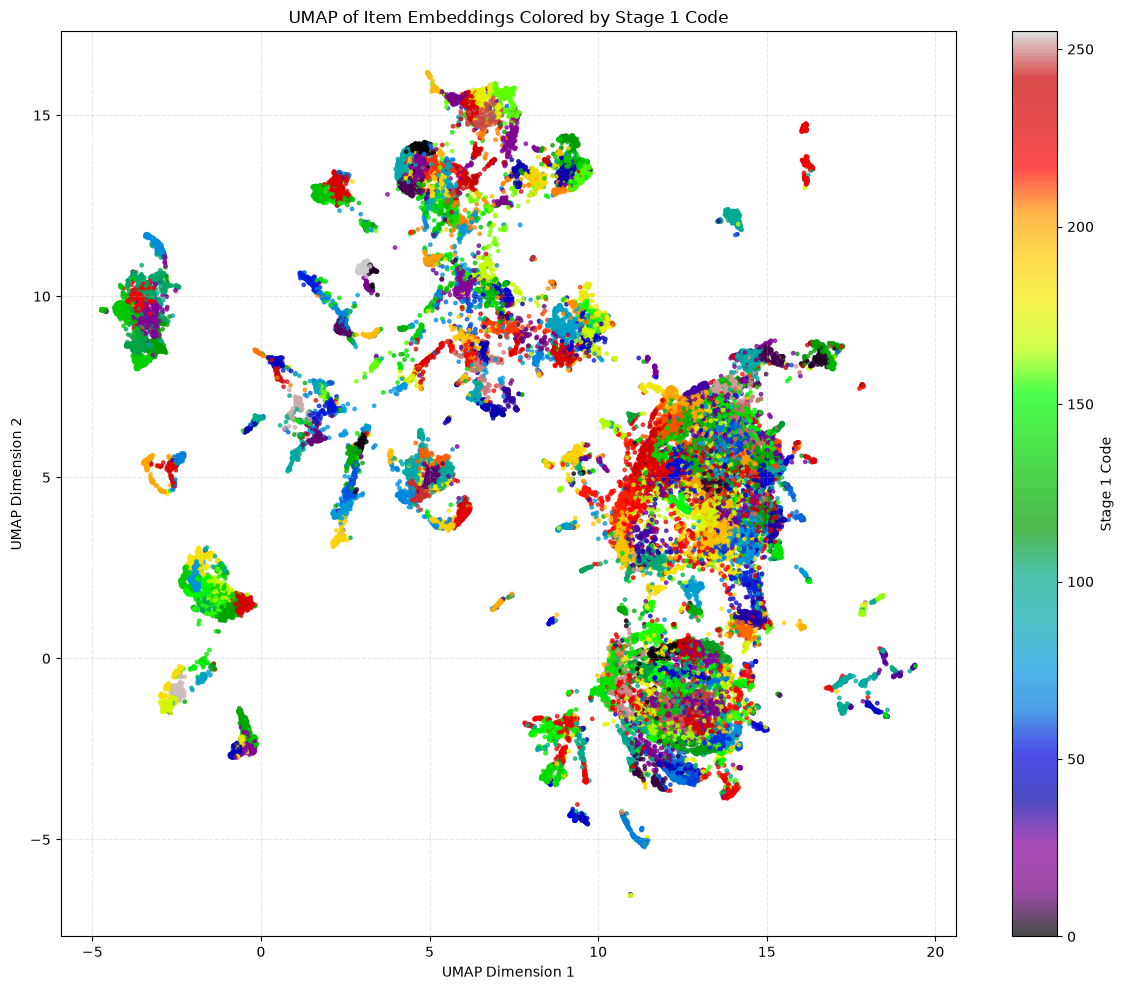

In [ ]:

# ==========================================
# B. UMAP of Embeddings Colored by Stage 0 Code
# ==========================================
import matplotlib.pyplot as plt
import umap

# 1. Extract Stage 1 codes from the aligned SID array
stage1_codes = sid_array[:, 0]

# 2. Project the same normalized embedding sample
print("Running UMAP on the shared embedding subset...")

reducer = umap.UMAP(
    n_components=2,
    random_state=RANDOM_SEED,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
)

embedding_2d = reducer.fit_transform(norm_embeddings)

# 3. Plot
fig, ax = plt.subplots(figsize=(12, 10))

scatter = ax.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    c=stage1_codes,
    cmap="nipy_spectral",
    s=6,
    alpha=0.7,
    vmin=0,
    vmax=255,
    rasterized=True,
)

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Stage 1 Code")

ax.set_title("UMAP of Item Embeddings Colored by Stage 0 Code")
ax.set_xlabel("UMAP Dimension 1")
ax.set_ylabel("UMAP Dimension 2")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


In [27]:

# ==========================================
# C. Nearest-Neighbor Prefix Preservation
# ==========================================
import faiss
import numpy as np

# 1. Build an exact cosine-similarity index
# Use a copy because Faiss normalization modifies the array in place.
faiss_embeddings = norm_embeddings.astype(np.float32, copy=True)

index = faiss.IndexFlatIP(faiss_embeddings.shape[1])
index.add(faiss_embeddings)

# 2. Retrieve nearest neighbors for each sampled item
K_NEIGHBORS = 10

if len(faiss_embeddings) <= K_NEIGHBORS:
    raise ValueError("Not enough items for the requested K.")

print(
    f"Searching {len(faiss_embeddings):,} items "
    f"for their top-{K_NEIGHBORS} neighbors..."
)

distances, neighbor_indices = index.search(
    faiss_embeddings,
    K_NEIGHBORS + 1,
)

# 3. Calculate matching prefix lengths, excluding the query itself
preservation_counts = np.zeros(
    sid_array.shape[1],
    dtype=np.int64,
)
total_checked = 0

for i in range(len(faiss_embeddings)):
    # Explicitly exclude the query by index.
    neighbors = neighbor_indices[i]
    neighbors = neighbors[neighbors != i][:K_NEIGHBORS]

    if len(neighbors) != K_NEIGHBORS:
        raise RuntimeError(
            f"Expected {K_NEIGHBORS} non-self neighbors for item {i}, "
            f"but found {len(neighbors)}."
        )

    query_sid = sid_array[i]
    neighbor_sids = sid_array[neighbors]

    # Compare all four stages
    stage_matches = neighbor_sids == query_sid[None, :]

    # Cumulative prefix agreement:
    # a match at stage 3 requires matches at stages 1, 2, and 3.
    prefix_matches = np.logical_and.accumulate(
        stage_matches, axis=1
    )

    preservation_counts += prefix_matches.sum(axis=0)
    total_checked += len(neighbors)

# 4. Report results
print("\n--- Nearest-Neighbor Prefix Preservation ---")
print(f"Queries: {len(faiss_embeddings):,}")
print(f"Neighbors per query: {K_NEIGHBORS}")
print(f"Total evaluated pairs: {total_checked:,}")

for stage, count in enumerate(preservation_counts, start=1):
    rate = 100.0 * count / total_checked

    print(
        f"At least {stage}-stage prefix match: "
        f"{rate:.2f}% ({count:,}/{total_checked:,})"
    )

Searching 50,000 items for their top-10 neighbors...

--- Nearest-Neighbor Prefix Preservation ---
Queries: 50,000
Neighbors per query: 10
Total evaluated pairs: 500,000
At least 1-stage prefix match: 71.81% (359,053/500,000)
At least 2-stage prefix match: 17.21% (86,064/500,000)
At least 3-stage prefix match: 2.58% (12,885/500,000)
At least 4-stage prefix match: 0.33% (1,663/500,000)


In [28]:
# ==========================================
# D. SID Prefix-Based Retrieval Evaluation
# ==========================================
import faiss
import numpy as np
import pandas as pd

# Configuration
K_NEIGHBORS = 10
NUM_QUERIES = 5_000

n_items = len(norm_embeddings)
n_stages = sid_array.shape[1]

if n_items <= K_NEIGHBORS:
    raise ValueError("Not enough items for top-K evaluation.")

if not np.isfinite(norm_embeddings).all():
    raise ValueError("Embeddings contain NaN or infinite values.")

if np.any(np.linalg.norm(norm_embeddings, axis=1) < 1e-12):
    raise ValueError("Zero-norm embeddings detected.")

# 1. Build an exact cosine-similarity index over the full sample
faiss_embeddings = np.ascontiguousarray(
    norm_embeddings, dtype=np.float32
)

index = faiss.IndexFlatIP(faiss_embeddings.shape[1])
index.add(faiss_embeddings)

# 2. Select reproducible query items
query_count = min(NUM_QUERIES, n_items)
query_indices = np.sort(
    rng.choice(n_items, size=query_count, replace=False)
)

query_embeddings = faiss_embeddings[query_indices]

# Retrieve K+1 to allow exclusion of the query itself
print(
    f"Searching {query_count:,} queries against "
    f"{n_items:,} catalogue items..."
)

distances, neighbor_indices = index.search(
    query_embeddings, K_NEIGHBORS + 1
)

# 3. Compute exact nearest neighbors, excluding each query item
true_neighbors = np.empty(
    (query_count, K_NEIGHBORS), dtype=np.int64
)

for row, query_idx in enumerate(query_indices):
    candidates = neighbor_indices[row]
    candidates = candidates[candidates != query_idx]

    if len(candidates) < K_NEIGHBORS:
        raise RuntimeError(
            f"Insufficient neighbors for query index {query_idx}."
        )

    true_neighbors[row] = candidates[:K_NEIGHBORS]

# 4. Build SID prefix group sizes over the full catalogue
# Prefix group sizes include the query item itself.
prefix_group_sizes = {}

for depth in range(1, n_stages + 1):
    counts = {}

    for sid in sid_array:
        prefix = tuple(sid[:depth])
        counts[prefix] = counts.get(prefix, 0) + 1

    prefix_group_sizes[depth] = counts

# 5. Measure prefix neighbor preservation and candidate reduction
query_sids = sid_array[query_indices]
neighbor_sids = sid_array[true_neighbors]

# Shape: (queries, K_NEIGHBORS, stages)
stage_matches = (
    neighbor_sids == query_sids[:, None, :]
)

# A match at depth d requires every preceding code to match.
prefix_matches = np.logical_and.accumulate(
    stage_matches, axis=2
)

results = []

for depth in range(1, n_stages + 1):
    # Number of true top-K neighbors contained in the prefix group
    hits_per_query = prefix_matches[:, :, depth - 1].sum(axis=1)

    # Recall = fraction of true top-K neighbors recovered
    recall_per_query = hits_per_query / K_NEIGHBORS

    # Candidate group size, excluding the query itself
    group_sizes = prefix_group_sizes[depth]
    candidate_counts = np.array([
        group_sizes[tuple(sid[:depth])] - 1
        for sid in query_sids
    ])

    # Random baseline: expected recall for a random candidate
    # set of the same size, sampled from the other N-1 items.
    random_recall_per_query = candidate_counts / (n_items - 1)

    # Candidate pool reduction relative to all other items
    candidate_fraction = candidate_counts / (n_items - 1)
    reduction = 1.0 - candidate_fraction

    results.append({
        "prefix_depth": depth,
        "recall_at_10": recall_per_query.mean(),
        "random_baseline_recall": random_recall_per_query.mean(),
        "mean_candidates": candidate_counts.mean(),
        "median_candidates": np.median(candidate_counts),
        "p90_candidates": np.percentile(candidate_counts, 90),
        "mean_candidate_fraction": candidate_fraction.mean(),
        "mean_candidate_reduction": reduction.mean(),
        "queries_with_zero_candidates": np.mean(
            candidate_counts == 0
        ),
    })

# 6. Display metrics
results_df = pd.DataFrame(results)

display_df = results_df.copy()

for col in [
    "recall_at_10",
    "random_baseline_recall",
    "mean_candidate_fraction",
    "mean_candidate_reduction",
    "queries_with_zero_candidates",
]:
    display_df[col] = (100 * display_df[col]).round(3)

display_df = display_df.rename(columns={
    "prefix_depth": "Prefix Depth",
    "recall_at_10": "Neighbor Recall@10 (%)",
    "random_baseline_recall": "Random Baseline (%)",
    "mean_candidates": "Mean Candidates",
    "median_candidates": "Median Candidates",
    "p90_candidates": "P90 Candidates",
    "mean_candidate_fraction": "Catalogue Fraction (%)",
    "mean_candidate_reduction": "Candidate Reduction (%)",
    "queries_with_zero_candidates": "Zero-Candidate Queries (%)",
})

print("\n--- SID Prefix Retrieval Results ---")
print(display_df.to_string(index=False, float_format=lambda x: f"{x:,.3f}"))


Searching 5,000 queries against 50,000 catalogue items...

--- SID Prefix Retrieval Results ---
 Prefix Depth  Neighbor Recall@10 (%)  Random Baseline (%)  Mean Candidates  Median Candidates  P90 Candidates  Catalogue Fraction (%)  Candidate Reduction (%)  Zero-Candidate Queries (%)
            1                  71.158                0.428          213.812            207.000         293.000                   0.428                   99.572                       0.000
            2                  16.828                0.008            4.134              2.000          10.000                   0.008                   99.992                      21.700
            3                   2.626                0.001            0.310              0.000           1.000                   0.001                   99.999                      84.000
            4                   0.346                0.000            0.036              0.000           0.000                   0.000                  

# Extra

In [3]:
# ==========================================
# 0. Shared Data Loading & Dynamic Prefix Selection
# ==========================================
import pyarrow.dataset as ds
import numpy as np
import pandas as pd

# Configuration
PARQUET_PATH = "./local/2026-13-10-1-ei/item_embeddings.parquet"
SAMPLE_SIZE = 50_000
RANDOM_SEED = 42
SID_COLUMNS = [0, 1, 2, 3]

# Reproducible random generator
rng = np.random.default_rng(RANDOM_SEED)

# 1. Load a reproducible random subset of embeddings
dataset = ds.dataset(PARQUET_PATH, format="parquet")
total_rows = dataset.count_rows()
sample_size = min(SAMPLE_SIZE, total_rows)

sampled_indices = rng.choice(
    total_rows,
    size=sample_size,
    replace=False,
)
sampled_indices.sort()

table = dataset.take(sampled_indices)

item_ids = table.column("item_id").to_numpy()
embeddings_matrix = np.vstack(
    table.column("embedding").to_pylist()
).astype(np.float32)

# 2. Create a common item-indexed embedding DataFrame
embeddings_df = pd.DataFrame(
    embeddings_matrix,
    index=pd.Index(item_ids, name="item_id"),
)

# 3. Validate and align SIDs by item ID
assert embeddings_df.index.is_unique, "Embedding item_ids must be unique."
assert df.index.is_unique, "SID dataframe index must be unique."
assert set(SID_COLUMNS).issubset(df.columns), f"Missing SID columns: {set(SID_COLUMNS) - set(df.columns)}"

missing_sid_ids = embeddings_df.index.difference(df.index)
if len(missing_sid_ids) > 0:
    raise ValueError(f"{len(missing_sid_ids)} sampled items have no SID mapping.")

sid_df = df.loc[embeddings_df.index, SID_COLUMNS].copy()
sid_array = sid_df.to_numpy(dtype=np.int64)

# Normalize once for cosine similarity (Dot product of normalized vectors)
embedding_norms = np.linalg.norm(embeddings_matrix, axis=1, keepdims=True)
if np.any(embedding_norms < 1e-12):
    raise ValueError("Zero-norm embeddings found in the sample.")
norm_embeddings = embeddings_matrix / embedding_norms

print(f"Total parquet rows: {total_rows:,}")
print(f"Sampled items: {len(embeddings_df):,}")
print(f"Embedding shape: {embeddings_matrix.shape}")
print(f"SID shape: {sid_array.shape}")
print("-" * 50)


# ==========================================
# 4. Dynamic Prefix Selection from Sample
# ==========================================
# Convert SID columns to tuples for easy frequency counting within the sample
sid_tuples_2 = [tuple(v) for v in sid_array[:, :2]]
sid_tuples_3 = [tuple(v) for v in sid_array[:, :3]]

# Find the most common 2-stage and 3-stage prefixes present in THIS sample
from collections import Counter
common_2 = Counter(sid_tuples_2).most_common(1)[0][0]
common_3 = Counter(sid_tuples_3).most_common(1)[0][0]

print(f"Selected most frequent 2-stage prefix in sample: {common_2}")
print(f"Selected most frequent 3-stage prefix in sample: {common_3}")


# ==========================================
# 5. Cosine Similarity Calculations
# ==========================================
def compute_pairwise_similarities(mask, norm_embeddings, max_pairs=100_000):
    indices = np.where(mask)[0]
    if len(indices) < 2:
        return np.array([])
    
    sub_norms = norm_embeddings[indices]
    total_possible_pairs = len(indices) * (len(indices) - 1) // 2
    
    if total_possible_pairs > max_pairs:
        pair_indices = rng.choice(len(indices), size=(max_pairs, 2), replace=True)
        mask_diff = pair_indices[:, 0] != pair_indices[:, 1]
        pair_indices = pair_indices[mask_diff]
        sims = np.sum(sub_norms[pair_indices[:, 0]] * sub_norms[pair_indices[:, 1]], axis=1)
    else:
        sim_matrix = np.dot(sub_norms, sub_norms.T)
        triu_indices = np.triu_indices(len(indices), k=1)
        sims = sim_matrix[triu_indices]
        
    return sims

# A. Random Pairs Baseline
rand_u = rng.choice(sample_size, size=50_000, replace=True)
rand_v = rng.choice(sample_size, size=50_000, replace=True)
rand_mask = rand_u != rand_v
random_similarities = np.sum(
    norm_embeddings[rand_u[rand_mask]] * norm_embeddings[rand_v[rand_mask]], 
    axis=1
)

# B. 2-Stage Prefix Match
mask_2stage = (sid_array[:, 0] == common_2[0]) & (sid_array[:, 1] == common_2[1])
sims_2stage = compute_pairwise_similarities(mask_2stage, norm_embeddings)

# C. 3-Stage Prefix Match
mask_3stage = (
    (sid_array[:, 0] == common_3[0]) & 
    (sid_array[:, 1] == common_3[1]) & 
    (sid_array[:, 2] == common_3[2])
)
sims_3stage = compute_pairwise_similarities(mask_3stage, norm_embeddings)

# Print Results
print("\n--- Cosine Similarity Results ---")
print(f"Random Pairs       -> Count: {len(random_similarities):,} | Mean Sim: {random_similarities.mean():.4f}")
print(f"2-Stage {common_2} -> Count: {len(sims_2stage):,} | Mean Sim: {sims_2stage.mean():.4f}")
print(f"3-Stage {common_3} -> Count: {len(sims_3stage):,} | Mean Sim: {sims_3stage.mean():.4f}")

Total parquet rows: 4,783,154
Sampled items: 50,000
Embedding shape: (50000, 256)
SID shape: (50000, 4)
--------------------------------------------------
Selected most frequent 2-stage prefix in sample: (np.int64(31), np.int64(235))
Selected most frequent 3-stage prefix in sample: (np.int64(178), np.int64(77), np.int64(157))

--- Cosine Similarity Results ---
Random Pairs       -> Count: 49,997 | Mean Sim: 0.0836
2-Stage (np.int64(31), np.int64(235)) -> Count: 1,326 | Mean Sim: 0.8589
3-Stage (np.int64(178), np.int64(77), np.int64(157)) -> Count: 120 | Mean Sim: 0.9352


In [16]:
# ==========================================
# Hierarchical Feature Profiling via Sampled Parquet
# ==========================================
import pyarrow.dataset as ds
import numpy as np
import pandas as pd
from collections import Counter

# Configuration
PARQUET_PATH = "data/item_feat.parquet"  # Adjust to your items parquet path
SAMPLE_SIZE = 50_000
RANDOM_SEED = 42
SID_COLUMNS = [0, 1, 2]  # Need up to 3 stages
FEATURE_COLS = [100, 101, 102, 112, 114, 115, 116, 117, 118, 119, 120, 121, 122]

rng = np.random.default_rng(RANDOM_SEED)

# 1. Load a reproducible random subset from item.parquet
dataset = ds.dataset(PARQUET_PATH, format="parquet")
total_rows = dataset.count_rows()
sample_size = min(SAMPLE_SIZE, total_rows)

sampled_indices = rng.choice(total_rows, size=sample_size, replace=False)
sampled_indices.sort()

table = dataset.take(sampled_indices)
sampled_df = table.to_pandas()

# Ensure item_id is set as index for alignment
if "item_id" in sampled_df.columns:
    sampled_df.set_index("item_id", inplace=True)

# 2. Align with your main `df` SIDs
common_ids = sampled_df.index.intersection(df.index)
sampled_df = sampled_df.loc[common_ids]
sample_sid_df = df.loc[common_ids, SID_COLUMNS].copy()

# Convert FEATURE_COLS to strings to match sampled_df columns
feature_cols_str = [str(c) for c in FEATURE_COLS]
valid_features = [c for c in feature_cols_str if c in sampled_df.columns]

# Rebuild analysis_df cleanly by concatenating SID data and item features
analysis_df = pd.concat([sample_sid_df, sampled_df[valid_features]], axis=1)

# Create tuple representations for both 2-stage (parent) and 3-stage SIDs
analysis_df['sid_tuple_2'] = list(zip(analysis_df[0], analysis_df[1]))
analysis_df['sid_tuple_3'] = list(zip(analysis_df[0], analysis_df[1], analysis_df[2]))

print(f"Sampled overlapping items: {len(analysis_df):,}")
print("-" * 60)

# 3. Find the top 2 most frequent 3-stage prefixes AND extract their parent 2-stage prefixes
top_3_prefixes = [prefix for prefix, count in Counter(analysis_df['sid_tuple_3']).most_common(2)]
top_2_parents = [(p[0], p[1]) for p in top_3_prefixes]

print(f"Top 2 Frequent 3-Stage Prefixes:")
print(f"  1. {top_3_prefixes[0]} (Parent 2-Stage: {top_2_parents[0]})")
print(f"  2. {top_3_prefixes[1]} (Parent 2-Stage: {top_2_parents[1]})")
print("-" * 60)

# 4. Hierarchical Feature Comparison
feat_to_inspect = "100"  # String key matching Table 5/Table 2 columns
col_to_use = feat_to_inspect if feat_to_inspect in analysis_df.columns else int(feat_to_inspect)

if col_to_use in analysis_df.columns:
    # Subsets for 3-stage leaf nodes
    group_3a = analysis_df[analysis_df['sid_tuple_3'] == top_3_prefixes[0]]
    group_3b = analysis_df[analysis_df['sid_tuple_3'] == top_3_prefixes[1]]
    
    # Subsets for parent 2-stage nodes (containing the children)
    group_2a = analysis_df[analysis_df['sid_tuple_2'] == top_2_parents[0]]
    group_2b = analysis_df[analysis_df['sid_tuple_2'] == top_2_parents[1]]
    
    print(f"\n[Hierarchy Level 2] Parent Prefix {top_2_parents[0]} (n={len(group_2a)}) vs {top_2_parents[1]} (n={len(group_2b)})")
    print(f"--- Feature {feat_to_inspect} Top Values (Parent A) ---")
    print(group_2a[col_to_use].value_counts(normalize=True).head(3) * 100)
    print(f"--- Feature {feat_to_inspect} Top Values (Parent B) ---")
    print(group_2b[col_to_use].value_counts(normalize=True).head(3) * 100)

    print(f"\n[Hierarchy Level 3] Child Prefix {top_3_prefixes[0]} (n={len(group_3a)}) vs {top_3_prefixes[1]} (n={len(group_3b)})")
    print(f"--- Feature {feat_to_inspect} Top Values (Child A) ---")
    print(group_3a[col_to_use].value_counts(normalize=True).head(3) * 100)
    print(f"--- Feature {feat_to_inspect} Top Values (Child B) ---")
    print(group_3b[col_to_use].value_counts(normalize=True).head(3) * 100)
else:
    print(f"Feature column {feat_to_inspect} not found in analysis_df.")

Sampled overlapping items: 50,000
------------------------------------------------------------
Top 2 Frequent 3-Stage Prefixes:
  1. (178, 77, 157) (Parent 2-Stage: (178, 77))
  2. (188, 224, 122) (Parent 2-Stage: (188, 224))
------------------------------------------------------------

[Hierarchy Level 2] Parent Prefix (178, 77) (n=37) vs (188, 224) (n=18)
--- Feature 100 Top Values (Parent A) ---
100
6.0    89.189189
4.0    10.810811
Name: proportion, dtype: float64
--- Feature 100 Top Values (Parent B) ---
100
6.0    100.0
Name: proportion, dtype: float64

[Hierarchy Level 3] Child Prefix (178, 77, 157) (n=16) vs (188, 224, 122) (n=15)
--- Feature 100 Top Values (Child A) ---
100
6.0    87.5
4.0    12.5
Name: proportion, dtype: float64
--- Feature 100 Top Values (Child B) ---
100
6.0    100.0
Name: proportion, dtype: float64


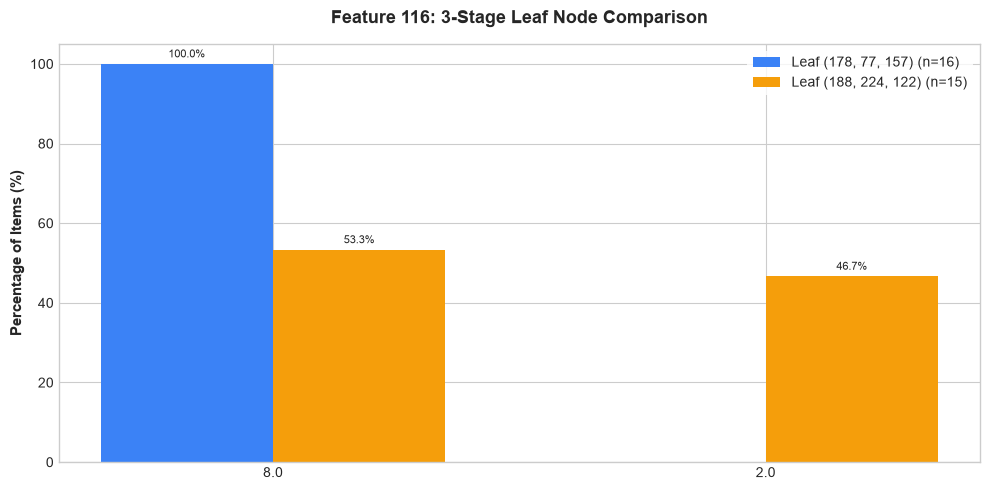

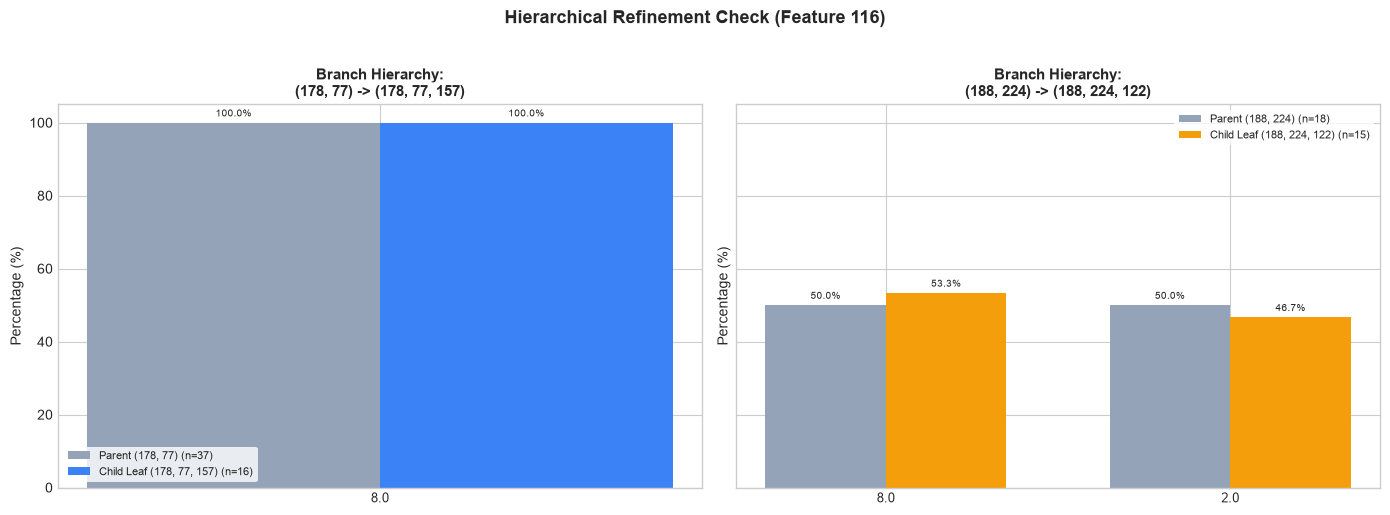

In [32]:
import matplotlib.pyplot as plt
import numpy as np

# Set clean minimalist style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

feat_to_inspect = "116"  # Choose the categorical feature column to plot
col_to_use = feat_to_inspect if feat_to_inspect in analysis_df.columns else int(feat_to_inspect)

if col_to_use in analysis_df.columns:
    # 1. Prepare Data Subsets
    group_3a = analysis_df[analysis_df['sid_tuple_3'] == top_3_prefixes[0]]
    group_3b = analysis_df[analysis_df['sid_tuple_3'] == top_3_prefixes[1]]
    
    group_2a = analysis_df[analysis_df['sid_tuple_2'] == top_2_parents[0]]
    group_2b = analysis_df[analysis_df['sid_tuple_2'] == top_2_parents[1]]

    # ==========================================
    # PLOT 1: 3-Stage vs 3-Stage Leaf Comparison
    # ==========================================
    fig, ax = plt.subplots(figsize=(10, 5))
    
    top_cats_3 = pd.concat([group_3a[col_to_use], group_3b[col_to_use]]).value_counts().head(5).index
    pct_3a = group_3a[col_to_use].value_counts(normalize=True).reindex(top_cats_3, fill_value=0) * 100
    pct_3b = group_3b[col_to_use].value_counts(normalize=True).reindex(top_cats_3, fill_value=0) * 100
    
    x = np.arange(len(top_cats_3))
    width = 0.35
    
    rects1 = ax.bar(x - width/2, pct_3a, width, label=f'Leaf {top_3_prefixes[0]} (n={len(group_3a):,})', color='#3b82f6')
    rects2 = ax.bar(x + width/2, pct_3b, width, label=f'Leaf {top_3_prefixes[1]} (n={len(group_3b):,})', color='#f59e0b')
    
    ax.set_ylabel('Percentage of Items (%)', fontsize=11, fontweight='bold')
    ax.set_title(f'Feature {feat_to_inspect}: 3-Stage Leaf Node Comparison', fontsize=13, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels([str(c) for c in top_cats_3], fontsize=10)
    ax.legend(frameon=True, facecolor='white', edgecolor='none')
    ax.set_ylim(0, 105)
    
    for rects in [rects1, rects2]:
        for bar in rects:
            h = bar.get_height()
            if h > 0:
                ax.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, h),
                            xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8)

    plt.tight_layout()
    plt.show()

    # ==========================================
    # PLOT 2 & 3: Hierarchical Comparisons (Child vs Parent)
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    
    # Helper plotting function for hierarchy
    def plot_hierarchy_pair(ax_sub, parent_group, child_group, parent_label, child_label, color_p, color_c):
        top_cats = pd.concat([parent_group[col_to_use], child_group[col_to_use]]).value_counts().head(4).index
        p_pct = parent_group[col_to_use].value_counts(normalize=True).reindex(top_cats, fill_value=0) * 100
        c_pct = child_group[col_to_use].value_counts(normalize=True).reindex(top_cats, fill_value=0) * 100
        
        x_sub = np.arange(len(top_cats))
        w = 0.35
        
        r1 = ax_sub.bar(x_sub - w/2, p_pct, w, label=f'Parent {parent_label} (n={len(parent_group):,})', color=color_p)
        r2 = ax_sub.bar(x_sub + w/2, c_pct, w, label=f'Child Leaf {child_label} (n={len(child_group):,})', color=color_c)
        
        ax_sub.set_title(f'Branch Hierarchy:\n{parent_label} -> {child_label}', fontsize=11, fontweight='bold')
        ax_sub.set_ylabel('Percentage (%)', fontsize=10)
        ax_sub.set_xticks(x_sub)
        ax_sub.set_xticklabels([str(c) for c in top_cats], fontsize=9)
        ax_sub.legend(frameon=True, facecolor='white', edgecolor='none', fontsize=8)
        ax_sub.set_ylim(0, 105)
        
        for rects in [r1, r2]:
            for bar in rects:
                h = bar.get_height()
                if h > 0:
                    ax_sub.annotate(f'{h:.1f}%', xy=(bar.get_x() + bar.get_width() / 2, h),
                                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=7)

    plot_hierarchy_pair(axes[0], group_2a, group_3a, str(top_2_parents[0]), str(top_3_prefixes[0]), '#94a3b8', '#3b82f6')
    plot_hierarchy_pair(axes[1], group_2b, group_3b, str(top_2_parents[1]), str(top_3_prefixes[1]), '#94a3b8', '#f59e0b')

    plt.suptitle(f'Hierarchical Refinement Check (Feature {feat_to_inspect})', fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

else:
    print(f"Feature {feat_to_inspect} not found.")